<a href="https://colab.research.google.com/github/Jonatham1542/Proyecto-Tornado/blob/main/proyectornado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# UIS - CÁLCULO CIENTÍFICO
# PROYECTO FINAL: SIMULACIÓN DE UN TORNADO
# ============================================================

%pip -q install numpy numba matplotlib pandas ipywidgets psutil

import os
import json
import platform
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import ipywidgets as widgets
import numba
import psutil

from pathlib import Path
from time import perf_counter
from matplotlib.patches import Circle
from IPython.display import display, HTML, clear_output
from numba import set_num_threads

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

Path("figuras").mkdir(exist_ok=True)
Path("resultados").mkdir(exist_ok=True)

# Parámetros físicos
R = 20.0
VMAX = 40.0

# Parámetros computacionales
DT = 0.01
PASOS = 400
N = 10000

plt.rcParams["figure.dpi"] = 110
plt.rcParams["animation.embed_limit"] = 100

print("SIMULACIÓN DE TORNADO")
print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Numba:", numba.__version__)
print("Configuración completada.")

SIMULACIÓN DE TORNADO
Python: 3.13.18
NumPy: 2.4.6
Numba: 0.64.0
Configuración completada.


In [ ]:
%%writefile modelo_tornado.py
import numpy as np
from numba import njit


def generar_particulas(n, semilla=42,
                       r_min=5.0, r_max=85.0):

    if n < 1 or r_min < 0 or r_max <= r_min:
        raise ValueError("Parámetros inválidos")

    rng = np.random.default_rng(semilla)

    angulos = rng.uniform(0, 2*np.pi, n)

    radios = np.sqrt(
        rng.uniform(r_min**2, r_max**2, n)
    )

    x = np.ascontiguousarray(
        radios * np.cos(angulos)
    )

    y = np.ascontiguousarray(
        radios * np.sin(angulos)
    )

    return x, y


def campo_velocidad(x, y, R, Vmax):

    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)

    r2 = x*x + y*y

    factor = np.where(
        r2 <= R*R,
        Vmax/R,
        Vmax*R/np.maximum(r2, 1e-30)
    )

    vx = -factor*y
    vy = factor*x

    return vx, vy


@njit(cache=True)
def avanzar_rk2(x, y, dt, R, Vmax):

    # Primera evaluación de velocidad
    r2 = x*x + y*y

    if r2 <= R*R:
        factor = Vmax/R
    else:
        factor = Vmax*R/r2

    k1x = -factor*y
    k1y = factor*x

    # Punto medio
    xm = x + 0.5*dt*k1x
    ym = y + 0.5*dt*k1y

    r2m = xm*xm + ym*ym

    if r2m <= R*R:
        factor_m = Vmax/R
    else:
        factor_m = Vmax*R/r2m

    # Segunda evaluación y posición siguiente
    xn = x - dt*factor_m*ym
    yn = y + dt*factor_m*xm

    return xn, yn


@njit(cache=True)
def guardar_trayectorias(x0, y0, dt,
                         pasos, cada, R, Vmax):

    n = len(x0)
    cuadros = pasos//cada + 1

    xs = np.empty((cuadros, n))
    ys = np.empty((cuadros, n))

    x = x0.copy()
    y = y0.copy()

    xs[0, :] = x
    ys[0, :] = y

    cuadro = 1

    for paso in range(1, pasos + 1):

        for i in range(n):

            x[i], y[i] = avanzar_rk2(
                x[i], y[i], dt, R, Vmax
            )

        if paso % cada == 0:

            xs[cuadro, :] = x
            ys[cuadro, :] = y
            cuadro += 1

    return xs, ys


def solucion_analitica(x0, y0, tiempo, R, Vmax):

    r2 = x0*x0 + y0*y0

    omega = np.where(
        r2 <= R*R,
        Vmax/R,
        Vmax*R/np.maximum(r2, 1e-30)
    )

    angulo = omega*tiempo

    x = (
        x0*np.cos(angulo)
        - y0*np.sin(angulo)
    )

    y = (
        x0*np.sin(angulo)
        + y0*np.cos(angulo)
    )

    return x, y

Writing modelo_tornado.py


In [ ]:
%%writefile serial.py
import numpy as np
from numba import njit
from modelo_tornado import avanzar_rk2


@njit(cache=True)
def simular_serial(x0, y0, dt, pasos, R, Vmax):

    x = np.empty_like(x0)
    y = np.empty_like(y0)

    for i in range(len(x0)):

        xi = x0[i]
        yi = y0[i]

        for k in range(pasos):

            xi, yi = avanzar_rk2(
                xi, yi, dt, R, Vmax
            )

        x[i] = xi
        y[i] = yi

    return x, y

Writing serial.py


In [ ]:
%%writefile paralelo.py
import numpy as np
from numba import njit, prange
from modelo_tornado import avanzar_rk2


@njit(cache=True, parallel=True)
def simular_paralelo(x0, y0, dt, pasos, R, Vmax):

    x = np.empty_like(x0)
    y = np.empty_like(y0)

    for i in prange(len(x0)):

        xi = x0[i]
        yi = y0[i]

        for k in range(pasos):

            xi, yi = avanzar_rk2(
                xi, yi, dt, R, Vmax
            )

        x[i] = xi
        y[i] = yi

    return x, y

Writing paralelo.py


In [ ]:
from modelo_tornado import (
    generar_particulas,
    campo_velocidad,
    guardar_trayectorias,
    solucion_analitica
)

from serial import simular_serial
from paralelo import simular_paralelo

# Compilar ambas funciones
x_test, y_test = generar_particulas(20)

simular_serial(
    x_test, y_test, DT, 10, R, VMAX
)

set_num_threads(1)

simular_paralelo(
    x_test, y_test, DT, 10, R, VMAX
)

# Verificación para diferentes tamaños
registros = []

for n in [100, 2000, 10000]:

    x0, y0 = generar_particulas(n)

    xs, ys = simular_serial(
        x0, y0, DT, PASOS, R, VMAX
    )

    xp, yp = simular_paralelo(
        x0, y0, DT, PASOS, R, VMAX
    )

    xa, ya = solucion_analitica(
        x0, y0, DT*PASOS, R, VMAX
    )

    error_paralelo = np.max(
        np.hypot(xs - xp, ys - yp)
    )

    error_analitico = np.max(
        np.hypot(xs - xa, ys - ya)
    )

    coinciden = (
        np.allclose(xs, xp, rtol=1e-12, atol=1e-12)
        and
        np.allclose(ys, yp, rtol=1e-12, atol=1e-12)
    )

    registros.append({
        "particulas": n,
        "error_serial_paralelo_m": error_paralelo,
        "error_analitico_m": error_analitico,
        "coinciden": coinciden
    })

    assert coinciden, "Error en la verificación"

verificacion = pd.DataFrame(registros)

display(verificacion)

verificacion.to_csv(
    "resultados/verificacion.csv",
    index=False
)

print("VERIFICACIÓN COMPLETADA")

,particulas,error_serial_paralelo_m,error_analitico_m,coinciden
0,100,0.0,0.009954,True
1,2000,0.0,0.010640,True
2,10000,0.0,0.010650,True


VERIFICACIÓN COMPLETADA


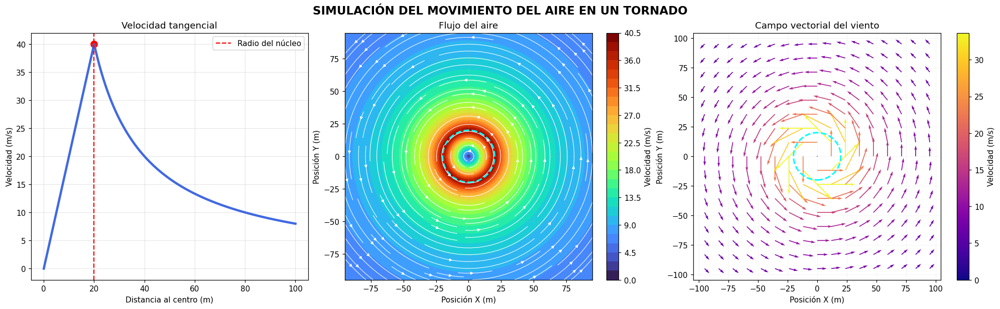

In [ ]:
# ============================================================
# VISUALIZACIÓN DEL CAMPO DE VELOCIDADES
# ============================================================

def mostrar_campo(radio, velocidad, guardar=False):

    # Perfil de velocidad tangencial
    r = np.linspace(0, 100, 500)

    v = np.where(
        r <= radio,
        velocidad*r/radio,
        velocidad*radio/np.maximum(r, 1e-30)
    )

    # Malla bidimensional
    ejes = np.linspace(-95, 95, 65)

    X, Y = np.meshgrid(ejes, ejes)

    VX, VY = campo_velocidad(
        X, Y, radio, velocidad
    )

    rapidez = np.hypot(VX, VY)

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 5.5),
        constrained_layout=True
    )

    # --------------------------------------------------------
    # GRÁFICA 1: PERFIL DE VELOCIDAD
    # --------------------------------------------------------

    axes[0].plot(
        r, v,
        color="royalblue",
        linewidth=3
    )

    axes[0].axvline(
        radio,
        color="red",
        linestyle="--",
        label="Radio del núcleo"
    )

    axes[0].scatter(
        [radio], [velocidad],
        color="red",
        s=75
    )

    axes[0].set_title("Velocidad tangencial")
    axes[0].set_xlabel("Distancia al centro (m)")
    axes[0].set_ylabel("Velocidad (m/s)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # --------------------------------------------------------
    # GRÁFICA 2: MAPA DE VELOCIDADES
    # --------------------------------------------------------

    mapa = axes[1].contourf(
        X, Y, rapidez,
        levels=30,
        cmap="turbo",
        vmin=0,
        vmax=velocidad
    )

    axes[1].streamplot(
        X, Y, VX, VY,
        color="white",
        density=1.2,
        linewidth=0.7,
        arrowsize=0.8
    )

    fig.colorbar(
        mapa,
        ax=axes[1],
        label="Velocidad (m/s)"
    )

    axes[1].set_title("Flujo del aire")

    # --------------------------------------------------------
    # GRÁFICA 3: VECTORES DE VELOCIDAD
    # --------------------------------------------------------

    flechas = axes[2].quiver(
        X[::4, ::4],
        Y[::4, ::4],
        VX[::4, ::4],
        VY[::4, ::4],
        rapidez[::4, ::4],
        cmap="plasma",
        scale=220
    )

    fig.colorbar(
        flechas,
        ax=axes[2],
        label="Velocidad (m/s)"
    )

    axes[2].set_title("Campo vectorial del viento")

    # Núcleo del tornado
    for ax in axes[1:]:

        ax.add_patch(
            Circle(
                (0, 0),
                radio,
                fill=False,
                edgecolor="cyan",
                linewidth=2,
                linestyle="--"
            )
        )

        ax.set_aspect("equal")
        ax.set_xlabel("Posición X (m)")
        ax.set_ylabel("Posición Y (m)")
        ax.grid(alpha=0.1)

    fig.suptitle(
        "SIMULACIÓN DEL MOVIMIENTO DEL AIRE EN UN TORNADO",
        fontsize=15,
        fontweight="bold"
    )

    if guardar:
        fig.savefig(
            "figuras/modelo_fisico.png",
            dpi=200,
            bbox_inches="tight"
        )

    display(fig)
    plt.close(fig)


# Generar las gráficas iniciales
mostrar_campo(R, VMAX, guardar=True)

In [ ]:
# ============================================================
# ANIMACIÓN DE PARTÍCULAS DEL TORNADO
# ============================================================

from matplotlib.animation import FuncAnimation

def crear_animacion(
    radio=20.0,
    velocidad=40.0,
    n=300,
    duracion=12.0,
    pasos=600,
    cada=10
):

    # Condiciones iniciales
    x0, y0 = generar_particulas(
        n, semilla=42
    )

    dt = duracion/pasos

    # Trayectorias numéricas
    tx, ty = guardar_trayectorias(
        x0, y0,
        dt, pasos, cada,
        radio, velocidad
    )

    # Figura
    fig, ax = plt.subplots(figsize=(7, 7))

    fig.patch.set_facecolor("#071321")
    ax.set_facecolor("#071321")

    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_aspect("equal")

    ax.set_title(
        "TORNADO: MOVIMIENTO DEL AIRE",
        color="white",
        fontsize=16,
        fontweight="bold"
    )

    ax.set_xlabel("X (m)", color="white")
    ax.set_ylabel("Y (m)", color="white")

    ax.tick_params(colors="white")
    ax.grid(alpha=0.12, color="white")

    # Núcleo
    ax.add_patch(
        Circle(
            (0, 0),
            radio,
            fill=False,
            edgecolor="cyan",
            linestyle="--",
            linewidth=2
        )
    )

    # Colores de las partículas
    radios_iniciales = np.hypot(x0, y0)

    puntos = ax.scatter(
        tx[0],
        ty[0],
        c=radios_iniciales,
        cmap="plasma",
        vmin=0,
        vmax=85,
        s=13,
        alpha=0.9
    )

    # Trayectorias visibles de algunas partículas
    cantidad_estelas = min(15, n)

    estelas = []

    for i in range(cantidad_estelas):

        linea, = ax.plot(
            [], [],
            color="#8ddfff",
            linewidth=0.8,
            alpha=0.65
        )

        estelas.append(linea)

    # Reloj
    reloj = ax.text(
        0.03, 0.95,
        "",
        transform=ax.transAxes,
        color="white",
        fontsize=12,
        verticalalignment="top"
    )

    # Información
    ax.text(
        0.03, 0.03,
        f"Vmax = {velocidad} m/s | R = {radio} m",
        transform=ax.transAxes,
        color="white",
        fontsize=10
    )

    # --------------------------------------------------------
    # ACTUALIZACIÓN DE LA ANIMACIÓN
    # --------------------------------------------------------

    def actualizar(frame):

        posiciones = np.column_stack((
            tx[frame],
            ty[frame]
        ))

        puntos.set_offsets(posiciones)

        # Dibujar pequeñas estelas de movimiento
        inicio = max(0, frame - 12)

        for i, linea in enumerate(estelas):

            linea.set_data(
                tx[inicio:frame+1, i],
                ty[inicio:frame+1, i]
            )

        tiempo = frame*cada*dt

        reloj.set_text(
            f"Tiempo simulado: {tiempo:.2f} s"
        )

        return (puntos, reloj, *estelas)

    # Crear animación
    anim = FuncAnimation(
        fig,
        actualizar,
        frames=tx.shape[0],
        interval=75,
        blit=False,
        repeat=True
    )

    html = anim.to_jshtml(
        fps=16,
        default_mode="loop"
    )

    plt.close(fig)

    return HTML(html)


# Mostrar animación
display(
    crear_animacion(
        radio=R,
        velocidad=VMAX,
        n=300,
        duracion=12
    )
)

In [ ]:
# ============================================================
# SIMULADOR INTERACTIVO DEL TORNADO
# ============================================================

# Control de radio
slider_radio = widgets.FloatSlider(
    value=20,
    min=10,
    max=40,
    step=2,
    description="Radio (m)",
    continuous_update=False,
    style={"description_width": "120px"}
)

# Control de velocidad
slider_velocidad = widgets.FloatSlider(
    value=40,
    min=10,
    max=80,
    step=5,
    description="Velocidad (m/s)",
    continuous_update=False,
    style={"description_width": "120px"}
)

# Número de partículas
slider_particulas = widgets.IntSlider(
    value=250,
    min=50,
    max=500,
    step=50,
    description="Partículas",
    continuous_update=False,
    style={"description_width": "120px"}
)

# Tiempo de simulación
slider_tiempo = widgets.IntSlider(
    value=10,
    min=4,
    max=16,
    step=1,
    description="Tiempo (s)",
    continuous_update=False,
    style={"description_width": "120px"}
)

# Botones
boton_campo = widgets.Button(
    description="Ver campo de viento",
    button_style="info",
    icon="area-chart"
)

boton_animar = widgets.Button(
    description="Animar tornado",
    button_style="success",
    icon="play"
)

salida_interactiva = widgets.Output()

# ------------------------------------------------------------
# ACCIONES DE LOS BOTONES
# ------------------------------------------------------------

def accion_campo(b):

    with salida_interactiva:

        clear_output(wait=True)

        mostrar_campo(
            slider_radio.value,
            slider_velocidad.value
        )


def accion_animar(b):

    with salida_interactiva:

        clear_output(wait=True)

        display(
            crear_animacion(
                radio=slider_radio.value,
                velocidad=slider_velocidad.value,
                n=slider_particulas.value,
                duracion=slider_tiempo.value
            )
        )


boton_campo.on_click(accion_campo)
boton_animar.on_click(accion_animar)

# Panel
panel = widgets.VBox([

    widgets.HTML(
        "<h2>🌪️ Laboratorio virtual del tornado</h2>"
    ),

    widgets.HTML(
        "<p>Modifica las propiedades del flujo "
        "y observa los resultados.</p>"
    ),

    slider_radio,
    slider_velocidad,
    slider_particulas,
    slider_tiempo,

    widgets.HBox([
        boton_campo,
        boton_animar
    ]),

    salida_interactiva
])

display(panel)

# Mostrar resultado inicial
accion_campo(None)

,dt_s,error_maximo_m
0,0.08,0.670126
1,0.04,0.167306
2,0.02,0.041821
3,0.01,0.010455


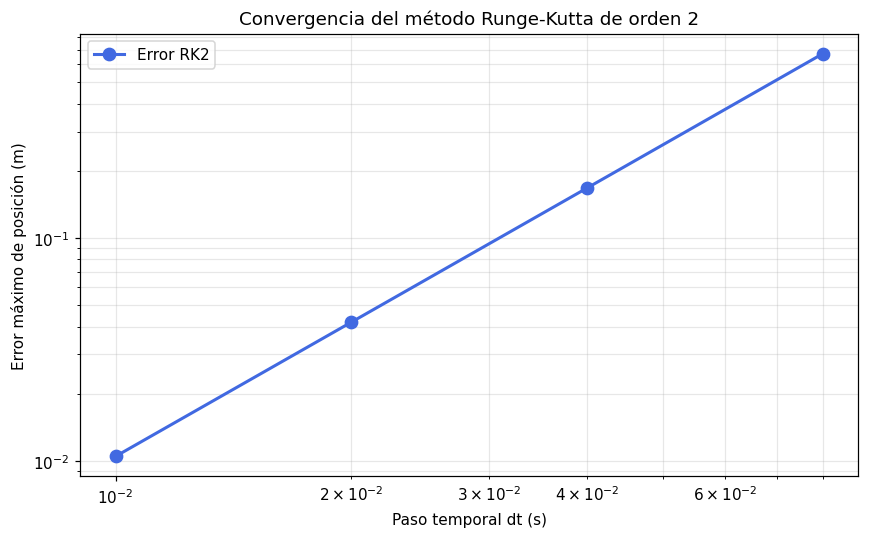

In [ ]:
# ============================================================
# CONVERGENCIA DEL MÉTODO NUMÉRICO
# ============================================================

x0, y0 = generar_particulas(
    500, semilla=123
)

tiempo_total = 4.0

lista_dt = [0.08, 0.04, 0.02, 0.01]

errores = []

# Solución analítica de referencia
xa, ya = solucion_analitica(
    x0, y0,
    tiempo_total,
    R, VMAX
)

for dt_prueba in lista_dt:

    pasos_prueba = int(
        round(tiempo_total/dt_prueba)
    )

    xf, yf = simular_serial(
        x0, y0,
        dt_prueba,
        pasos_prueba,
        R, VMAX
    )

    error = np.max(
        np.hypot(xf-xa, yf-ya)
    )

    errores.append(error)

tabla_convergencia = pd.DataFrame({
    "dt_s": lista_dt,
    "error_maximo_m": errores
})

display(tabla_convergencia)

tabla_convergencia.to_csv(
    "resultados/convergencia.csv",
    index=False
)

# Gráfica
fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(
    lista_dt,
    errores,
    "o-",
    color="royalblue",
    linewidth=2,
    markersize=8,
    label="Error RK2"
)

ax.set_title(
    "Convergencia del método Runge-Kutta de orden 2"
)

ax.set_xlabel("Paso temporal dt (s)")
ax.set_ylabel("Error máximo de posición (m)")
ax.grid(True, which="both", alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    "figuras/convergencia.png",
    dpi=200
)

plt.show()

In [ ]:
%%writefile medir.py

import os
import json
import platform
from time import perf_counter
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import numba

from numba import set_num_threads
from modelo_tornado import generar_particulas
from serial import simular_serial
from paralelo import simular_paralelo


def ejecutar_mediciones(
    tamanos=(2000, 10000, 40000),
    pasos=300,
    repeticiones=5,
    dt=0.01,
    R=20.0,
    Vmax=40.0
):

    Path("resultados").mkdir(exist_ok=True)

    # ========================================================
    # INFORMACIÓN DEL HARDWARE
    # ========================================================

    fisicos = psutil.cpu_count(logical=False) or 1
    logicos = psutil.cpu_count(logical=True) or 1

    if hasattr(os, "sched_getaffinity"):
        permitidos = len(os.sched_getaffinity(0))
    else:
        permitidos = logicos

    limite = max(
        1,
        min(
            fisicos,
            permitidos,
            numba.config.NUMBA_NUM_THREADS
        )
    )

    hilos = sorted(
        set(
            [p for p in [1, 2, 4, 8] if p <= limite]
            + [limite]
        )
    )

    print("Núcleos físicos reportados:", fisicos)
    print("CPU disponibles por afinidad:", permitidos)
    print("Hilos que se probarán:", hilos)

    # ========================================================
    # CALENTAMIENTO Y COMPILACIÓN JIT
    # ========================================================

    xt, yt = generar_particulas(20)

    simular_serial(
        xt, yt, dt, 10, R, Vmax
    )

    for p in hilos:

        set_num_threads(p)

        simular_paralelo(
            xt, yt, dt, 10, R, Vmax
        )

    # ========================================================
    # EXPERIMENTOS
    # ========================================================

    datos = []

    rng = np.random.default_rng(2026)

    for n in tamanos:

        x0, y0 = generar_particulas(
            n, semilla=42
        )

        tareas = [("Serial", 1)]

        tareas += [
            ("Paralelo", p) for p in hilos
        ]

        for repeticion in range(1, repeticiones + 1):

            # Variar el orden de las configuraciones
            orden = rng.permutation(len(tareas))

            for j in orden:

                modo, p = tareas[j]

                if modo == "Paralelo":
                    set_num_threads(p)

                inicio = perf_counter()

                if modo == "Serial":

                    simular_serial(
                        x0, y0,
                        dt, pasos,
                        R, Vmax
                    )

                else:

                    simular_paralelo(
                        x0, y0,
                        dt, pasos,
                        R, Vmax
                    )

                tiempo = perf_counter() - inicio

                datos.append({

                    "particulas": int(n),
                    "modo": modo,
                    "hilos": int(p),
                    "repeticion": repeticion,
                    "tiempo_s": tiempo

                })

        print(
            f"Mediciones terminadas: {n} partículas"
        )

    # ========================================================
    # RESUMEN ESTADÍSTICO
    # ========================================================

    mediciones = pd.DataFrame(datos)

    resumen = (
        mediciones.groupby(
            ["particulas", "modo", "hilos"],
            as_index=False
        )
        .agg(
            mediana_s=("tiempo_s", "median"),
            desv_s=("tiempo_s", "std"),
            min_s=("tiempo_s", "min"),
            max_s=("tiempo_s", "max")
        )
    )

    # ========================================================
    # SPEEDUP Y EFICIENCIA
    # ========================================================

    speed = []

    for n in tamanos:

        t1 = resumen.query(
            'particulas == @n and modo == "Serial"'
        )["mediana_s"].iloc[0]

        for p in hilos:

            tp = resumen.query(
                'particulas == @n and '
                'modo == "Paralelo" and hilos == @p'
            )["mediana_s"].iloc[0]

            aceleracion = t1/tp

            eficiencia = aceleracion/p

            speed.append({

                "particulas": int(n),
                "hilos": int(p),
                "tiempo_serial_s": t1,
                "tiempo_paralelo_s": tp,
                "speedup": aceleracion,
                "eficiencia": eficiencia

            })

    comparacion = pd.DataFrame(speed)

    # ========================================================
    # GUARDAR HARDWARE Y RESULTADOS
    # ========================================================

    hardware = {

        "python": platform.python_version(),
        "plataforma": platform.platform(),
        "procesador": platform.processor(),
        "cpu_fisicas_reportadas": fisicos,
        "cpu_logicas_reportadas": logicos,
        "cpu_disponibles_por_afinidad": permitidos,
        "hilos_numba_maximos":
            int(numba.config.NUMBA_NUM_THREADS),
        "hilos_probados": hilos,
        "ram_gb": round(
            psutil.virtual_memory().total/1024**3, 2
        ),
        "numba": numba.__version__,
        "numpy": np.__version__,
        "repeticiones": repeticiones,
        "pasos_temporales": pasos,
        "dt": dt,
        "radio": R,
        "velocidad_maxima": Vmax

    }

    mediciones.to_csv(
        "resultados/mediciones.csv",
        index=False
    )

    resumen.to_csv(
        "resultados/resumen.csv",
        index=False
    )

    comparacion.to_csv(
        "resultados/speedup_eficiencia.csv",
        index=False
    )

    with open(
        "resultados/hardware.json",
        "w",
        encoding="utf-8"
    ) as archivo:

        json.dump(
            hardware,
            archivo,
            indent=2,
            ensure_ascii=False
        )

    return mediciones, resumen, comparacion, hardware


if __name__ == "__main__":
    ejecutar_mediciones()

Writing medir.py


In [ ]:
# ============================================================
# EJECUTAR MEDICIONES DE TIEMPO
# ============================================================

from medir import ejecutar_mediciones

mediciones, resumen, comparacion, hardware = (
    ejecutar_mediciones(

        tamanos=(
            2000,
            10000,
            40000
        ),

        pasos=300,

        repeticiones=5,

        dt=DT,

        R=R,

        Vmax=VMAX

    )
)

print("\nTABLA DE TIEMPOS")
display(resumen)

print("\nSPEEDUP Y EFICIENCIA")
display(comparacion)

print("\nHARDWARE UTILIZADO")
print(json.dumps(
    hardware,
    indent=2,
    ensure_ascii=False
))

Núcleos físicos reportados: 1
CPU disponibles por afinidad: 2
Hilos que se probarán: [1]
Mediciones terminadas: 2000 partículas
Mediciones terminadas: 10000 partículas
Mediciones terminadas: 40000 partículas

TABLA DE TIEMPOS


,particulas,modo,hilos,mediana_s,desv_s,min_s,max_s
0,2000,Paralelo,1,0.018065,0.001086,0.016175,0.018653
1,2000,Serial,1,0.016676,0.000832,0.016209,0.018309
2,10000,Paralelo,1,0.083938,0.001365,0.082206,0.085847
3,10000,Serial,1,0.088573,0.005733,0.081542,0.097260
4,40000,Paralelo,1,0.324408,0.005391,0.320710,0.334233
5,40000,Serial,1,0.323399,0.001971,0.321264,0.326323



SPEEDUP Y EFICIENCIA


,particulas,hilos,tiempo_serial_s,tiempo_paralelo_s,speedup,eficiencia
0,2000,1,0.016676,0.018065,0.923107,0.923107
1,10000,1,0.088573,0.083938,1.055227,1.055227
2,40000,1,0.323399,0.324408,0.996889,0.996889



HARDWARE UTILIZADO
{
  "python": "3.13.18",
  "plataforma": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "procesador": "x86_64",
  "cpu_fisicas_reportadas": 1,
  "cpu_logicas_reportadas": 2,
  "cpu_disponibles_por_afinidad": 2,
  "hilos_numba_maximos": 2,
  "hilos_probados": [
    1
  ],
  "ram_gb": 12.67,
  "numba": "0.64.0",
  "numpy": "2.4.6",
  "repeticiones": 5,
  "pasos_temporales": 300,
  "dt": 0.01,
  "radio": 20.0,
  "velocidad_maxima": 40.0
}


No hay suficientes datos físicamente válidos para estimar f con Amdahl.


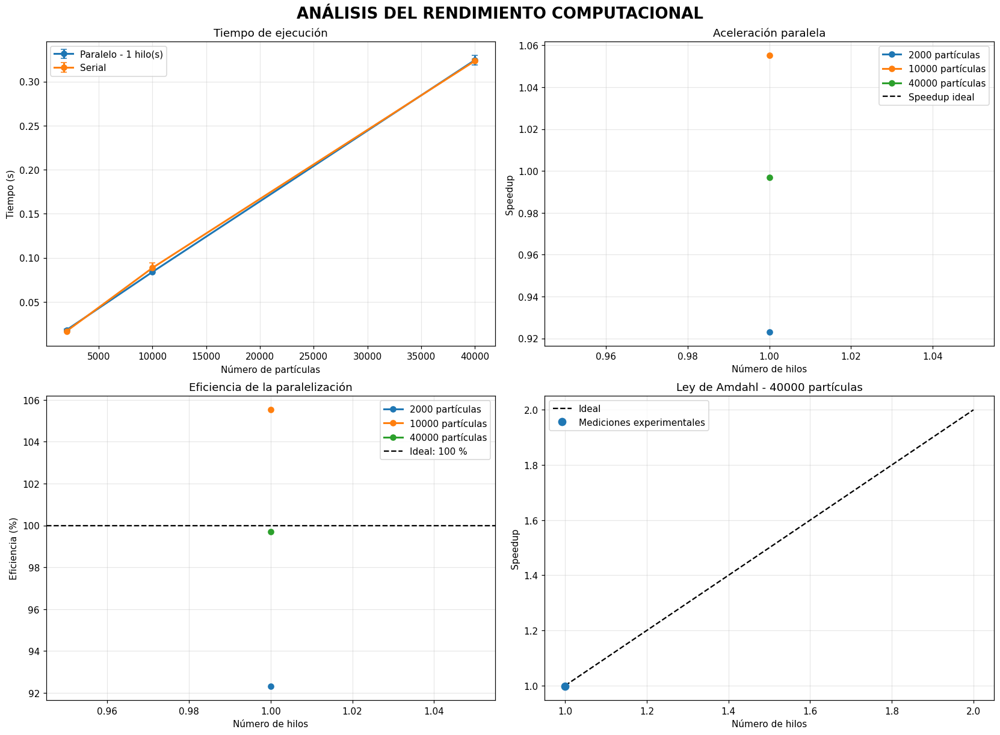

In [ ]:
# ============================================================
# ANÁLISIS GRÁFICO DEL RENDIMIENTO
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 11),
    constrained_layout=True
)

# ============================================================
# GRÁFICA 1 - TIEMPO DE EJECUCIÓN
# ============================================================

for (modo, hilos), grupo in resumen.groupby(
    ["modo", "hilos"]
):

    grupo = grupo.sort_values("particulas")

    if modo == "Serial":
        etiqueta = "Serial"
    else:
        etiqueta = f"Paralelo - {hilos} hilo(s)"

    axes[0, 0].errorbar(
        grupo["particulas"],
        grupo["mediana_s"],
        yerr=grupo["desv_s"],
        marker="o",
        capsize=3,
        linewidth=2,
        label=etiqueta
    )

axes[0, 0].set_title(
    "Tiempo de ejecución"
)

axes[0, 0].set_xlabel(
    "Número de partículas"
)

axes[0, 0].set_ylabel(
    "Tiempo (s)"
)

axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)


# ============================================================
# GRÁFICA 2 - SPEEDUP
# ============================================================

tamanos_medidos = sorted(
    comparacion["particulas"].unique()
)

hilos_medidos = sorted(
    comparacion["hilos"].unique()
)

for n in tamanos_medidos:

    grupo = comparacion[
        comparacion["particulas"] == n
    ].sort_values("hilos")

    axes[0, 1].plot(
        grupo["hilos"],
        grupo["speedup"],
        "o-",
        linewidth=2,
        label=f"{n} partículas"
    )

axes[0, 1].plot(
    hilos_medidos,
    hilos_medidos,
    "k--",
    label="Speedup ideal"
)

axes[0, 1].set_title(
    "Aceleración paralela"
)

axes[0, 1].set_xlabel(
    "Número de hilos"
)

axes[0, 1].set_ylabel(
    "Speedup"
)

axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)


# ============================================================
# GRÁFICA 3 - EFICIENCIA
# ============================================================

for n in tamanos_medidos:

    grupo = comparacion[
        comparacion["particulas"] == n
    ].sort_values("hilos")

    axes[1, 0].plot(
        grupo["hilos"],
        grupo["eficiencia"]*100,
        "o-",
        linewidth=2,
        label=f"{n} partículas"
    )

axes[1, 0].axhline(
    100,
    color="black",
    linestyle="--",
    label="Ideal: 100 %"
)

axes[1, 0].set_title(
    "Eficiencia de la paralelización"
)

axes[1, 0].set_xlabel(
    "Número de hilos"
)

axes[1, 0].set_ylabel(
    "Eficiencia (%)"
)

axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)


# ============================================================
# GRÁFICA 4 - LEY DE AMDAHL
# ============================================================

n_grande = max(tamanos_medidos)

datos_grandes = comparacion[
    comparacion["particulas"] == n_grande
].sort_values("hilos")

fracciones_estimadas = []

for _, fila in datos_grandes.iterrows():

    p = fila["hilos"]
    s = fila["speedup"]

    if p > 1:

        # Estimación de fracción paralelizable
        f = (1 - 1/s)/(1 - 1/p)

        if 0 <= f <= 1:
            fracciones_estimadas.append(f)

p_curva = np.linspace(
    1,
    max(2, max(hilos_medidos)),
    150
)

axes[1, 1].plot(
    p_curva,
    p_curva,
    "k--",
    label="Ideal"
)

if fracciones_estimadas:

    f_estimado = float(
        np.median(fracciones_estimadas)
    )

    amdahl = 1 / (
        (1 - f_estimado)
        + f_estimado/p_curva
    )

    axes[1, 1].plot(
        p_curva,
        amdahl,
        linewidth=2,
        label=f"Amdahl: f ≈ {f_estimado:.3f}"
    )

    print(
        "Fracción paralelizable estimada:",
        round(f_estimado, 4)
    )

else:

    print(
        "No hay suficientes datos físicamente "
        "válidos para estimar f con Amdahl."
    )

axes[1, 1].plot(
    datos_grandes["hilos"],
    datos_grandes["speedup"],
    "o",
    markersize=8,
    label="Mediciones experimentales"
)

axes[1, 1].set_title(
    f"Ley de Amdahl - {n_grande} partículas"
)

axes[1, 1].set_xlabel(
    "Número de hilos"
)

axes[1, 1].set_ylabel(
    "Speedup"
)

axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)


# ============================================================
# MOSTRAR Y GUARDAR
# ============================================================

fig.suptitle(
    "ANÁLISIS DEL RENDIMIENTO COMPUTACIONAL",
    fontsize=17,
    fontweight="bold"
)

fig.savefig(
    "figuras/rendimiento_completo.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# EXPORTACIÓN DEL PROYECTO COMPLETO
# ============================================================

import zipfile
import matplotlib
import ipywidgets

# ============================================================
# REQUIREMENTS
# ============================================================

requirements = f"""numpy=={np.__version__}
pandas=={pd.__version__}
matplotlib=={matplotlib.__version__}
numba=={numba.__version__}
ipywidgets=={ipywidgets.__version__}
psutil=={psutil.__version__}
"""

Path("requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

# ============================================================
# README
# ============================================================

readme = """# Simulación computacional de un tornado

Universidad Industrial de Santander
Cálculo Científico - Proyecto final

## Objetivo

Modelar el movimiento giratorio del aire mediante
el vórtice de Rankine, implementar una simulación
serial y paralela en Python y comparar su rendimiento.

## Modelo físico

Se utiliza un modelo bidimensional estacionario
de vórtice de Rankine:

v_theta = Vmax * r/R     si r <= R

v_theta = Vmax * R/r     si r > R

El modelo representa el movimiento circular
del aire y no reproduce la formación completa
de un tornado real.

## Método numérico

Runge-Kutta de segundo orden (RK2),
también conocido como método del punto medio.

## Implementaciones

- serial.py: versión secuencial compilada con Numba.
- paralelo.py: versión con Numba parallel=True y prange.
- modelo_tornado.py: ecuaciones y método numérico.
- medir.py: mediciones, speedup y eficiencia.

## Reproducibilidad

1. Instalar las dependencias de requirements.txt.
2. Ejecutar las celdas del notebook en orden.
3. Ejecutar python medir.py para repetir las mediciones.
4. Consultar resultados/hardware.json.
5. Consultar las gráficas en figuras/.

Las mediciones excluyen el primer tiempo de
compilación JIT mediante calentamiento previo.

Se realizan cinco repeticiones por configuración
y se utiliza la mediana de los tiempos.

El speedup se calcula respecto a la versión
serial compilada con Numba.

## Resultados

- Verificación serial/paralela.
- Comparación con solución analítica.
- Convergencia del método RK2.
- Campo de velocidades del tornado.
- Simulación animada con partículas.
- Simulador interactivo.
- Tiempo de ejecución.
- Speedup y eficiencia.
- Comparación con la ley de Amdahl.

## Limitaciones

El modelo es horizontal, bidimensional y
estacionario; no simula turbulencia, movimiento
vertical, formación de tornados ni interacción
con estructuras.

Los parámetros iniciales son ilustrativos.

## Referencias

NOAA - Tornado Basics
https://www.nssl.noaa.gov/education/svrwx101/tornadoes/

Wood y White (2011)
A New Parametric Model of Vortex Tangential-Wind
Profiles: Development, Testing, and Verification
https://doi.org/10.1175/2011JAS3588.1

Numba - Parallelization
https://numba.readthedocs.io/en/stable/user/parallel.html

NumPy - allclose
https://numpy.org/doc/stable/reference/generated/numpy.allclose.html

Python - perf_counter
https://docs.python.org/3/library/time.html#time.perf_counter
"""

Path("README.md").write_text(
    readme,
    encoding="utf-8"
)

# ============================================================
# COMPROBAR Y EMPAQUETAR ARCHIVOS
# ============================================================

archivos_codigo = [
    "modelo_tornado.py",
    "serial.py",
    "paralelo.py",
    "medir.py",
    "requirements.txt",
    "README.md"
]

archivos_generados = []

for nombre in archivos_codigo:

    ruta = Path(nombre)

    if ruta.exists():
        archivos_generados.append(ruta)

for carpeta in ["figuras", "resultados"]:

    archivos_generados.extend(
        p for p in Path(carpeta).rglob("*")
        if p.is_file()
    )

nombre_zip = "Proyecto_tornado_UIS.zip"

with zipfile.ZipFile(
    nombre_zip,
    "w",
    zipfile.ZIP_DEFLATED
) as archivo_zip:

    for ruta in archivos_generados:

        archivo_zip.write(
            ruta,
            arcname=str(ruta)
        )

print("=" * 55)
print("PROYECTO FINAL GENERADO")
print("=" * 55)

print("\nArchivos incluidos:")

for ruta in archivos_generados:
    print("✓", ruta)

print("\nArchivo comprimido:", nombre_zip)

# Descargar en Google Colab
try:

    from google.colab import files

    files.download(nombre_zip)

except ImportError:

    print(
        "El ZIP está disponible en:",
        Path(nombre_zip).resolve()
    )

print(
    "\nRecuerda guardar también el notebook "
    "desde Archivo > Descargar > Descargar .ipynb"
)

PROYECTO FINAL GENERADO

Archivos incluidos:
✓ modelo_tornado.py
✓ serial.py
✓ paralelo.py
✓ medir.py
✓ requirements.txt
✓ README.md
✓ figuras/rendimiento_completo.png
✓ figuras/convergencia.png
✓ figuras/modelo_fisico.png
✓ resultados/convergencia.csv
✓ resultados/verificacion.csv
✓ resultados/speedup_eficiencia.csv
✓ resultados/resumen.csv
✓ resultados/hardware.json
✓ resultados/mediciones.csv

Archivo comprimido: Proyecto_tornado_UIS.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Recuerda guardar también el notebook desde Archivo > Descargar > Descargar .ipynb
